# 2014 — Adam and the Evolution of Optimizers

**Papers:** Robbins & Monro (SGD, 1951); Polyak (momentum, 1964); Nesterov (1983); Duchi et al. (*AdaGrad*, 2011); Hinton (*RMSProp*, lecture notes 2012); Diederik Kingma & Jimmy Ba, *"Adam: A Method for Stochastic Optimization"* (2014); Loshchilov & Hutter, *"Decoupled Weight Decay Regularization"* (**AdamW**, 2017). Muon (2024) appears in notebook 74.

Gradient descent says *which way* is downhill. Optimizers decide *how far* to step, separately for every parameter:

| optimizer | update | idea |
|---|---|---|
| SGD | $\theta \leftarrow \theta - \eta g$ | plain step |
| Momentum | $m \leftarrow \beta m + g,\ \theta \leftarrow \theta - \eta m$ | heavy ball: accumulate velocity, damp zig-zags |
| RMSProp | $v \leftarrow \beta v + (1-\beta) g^2,\ \theta \leftarrow \theta - \eta g/\sqrt{v+\epsilon}$ | per-parameter step size, normalised by recent gradient scale |
| **Adam** | $m \leftarrow \beta_1 m + (1-\beta_1)g,\ v \leftarrow \beta_2 v + (1-\beta_2)g^2,\ \hat m = \frac{m}{1-\beta_1^t},\ \hat v=\frac{v}{1-\beta_2^t},\ \theta \leftarrow \theta - \eta \frac{\hat m}{\sqrt{\hat v}+\epsilon}$ | momentum + RMSProp + bias correction |
| **AdamW** | Adam, then $\theta \leftarrow \theta - \eta\lambda\theta$ | weight decay *decoupled* from the adaptive scaling |

AdamW (with warmup + cosine decay) became the default for training Transformers until Muon-style optimizers arrived.

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
class Optimizer:
    """All five written from scratch over a list of tensors."""
    def __init__(self, params, kind, lr, beta1=0.9, beta2=0.999, eps=1e-8, wd=0.0):
        self.p, self.kind, self.lr, self.b1, self.b2, self.eps, self.wd = list(params), kind, lr, beta1, beta2, eps, wd
        self.m = [torch.zeros_like(p) for p in self.p]; self.v = [torch.zeros_like(p) for p in self.p]; self.t = 0
    @torch.no_grad()
    def step(self):
        self.t += 1
        for p, m, v in zip(self.p, self.m, self.v):
            g = p.grad
            if self.kind == "sgd":
                p -= self.lr * g
            elif self.kind == "momentum":
                m.mul_(self.b1).add_(g); p -= self.lr * m
            elif self.kind == "rmsprop":
                v.mul_(self.b2).addcmul_(g, g, value=1 - self.b2); p -= self.lr * g / (v.sqrt() + self.eps)
            else:                                                       # adam / adamw
                m.mul_(self.b1).add_(g, alpha=1 - self.b1); v.mul_(self.b2).addcmul_(g, g, value=1 - self.b2)
                m_hat, v_hat = m / (1 - self.b1 ** self.t), v / (1 - self.b2 ** self.t)
                if self.kind == "adamw": p.mul_(1 - self.lr * self.wd)  # decoupled weight decay
                p -= self.lr * m_hat / (v_hat.sqrt() + self.eps)
    def zero_grad(self):
        for p in self.p: p.grad = None

# sanity check against PyTorch's AdamW
w1 = torch.randn(5, requires_grad=True); w2 = w1.detach().clone().requires_grad_(True)
mine, ref = Optimizer([w1], "adamw", 1e-2, wd=0.1), torch.optim.AdamW([w2], lr=1e-2, weight_decay=0.1)
for _ in range(10):
    for w, o in [(w1, mine), (w2, ref)]:
        o.zero_grad(); (w ** 3).sum().backward(); o.step()
print("max |mine - torch AdamW| after 10 steps:", (w1 - w2).abs().max().item())

max |mine - torch AdamW| after 10 steps: 1.1920928955078125e-07


## Trajectories on the Rosenbrock "banana" valley
$f(x,y) = (1-x)^2 + 100(y-x^2)^2$ has a long, curved, flat-bottomed valley with its minimum at (1, 1). Plain SGD has to use a tiny learning rate to avoid blowing up across the steep walls.

sgd       lr=0.001   final point [-0.66   0.444]  f = 2.7629
momentum  lr=0.0002  final point [0.564 0.316]  f = 0.1903
rmsprop   lr=0.01    final point [0.038 0.001]  f = 0.9259


adam      lr=0.05    final point [0.982 0.964]  f = 0.0003


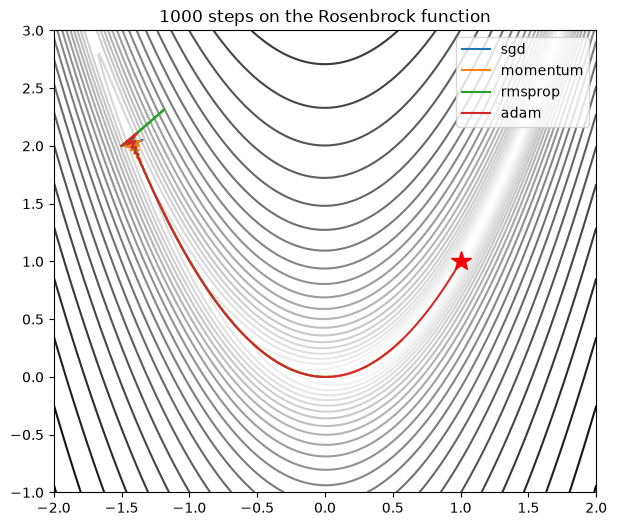

In [3]:
rosen = lambda p: (1 - p[0]) ** 2 + 100 * (p[1] - p[0] ** 2) ** 2
settings = {"sgd": 1e-3, "momentum": 2e-4, "rmsprop": 1e-2, "adam": 5e-2}
paths = {}
for kind, lr in settings.items():
    p = torch.tensor([-1.5, 2.0], requires_grad=True); o = Optimizer([p], kind, lr); path = [p.detach().clone()]
    for _ in range(1000):
        o.zero_grad(); rosen(p).backward(); o.step(); path.append(p.detach().clone())
    paths[kind] = torch.stack(path)
    print(f"{kind:9s} lr={lr:<7} final point {np.round(path[-1].numpy(), 3)}  f = {rosen(path[-1]).item():.4f}")
X, Y = np.meshgrid(np.linspace(-2, 2, 300), np.linspace(-1, 3, 300))
plt.figure(figsize=(7, 6)); plt.contour(X, Y, np.log1p((1 - X) ** 2 + 100 * (Y - X ** 2) ** 2), 30, cmap="Greys")
for k, pth in paths.items(): plt.plot(pth[:, 0], pth[:, 1], label=k, lw=1.5)
plt.plot(1, 1, "r*", ms=15); plt.legend(); plt.title("1000 steps on the Rosenbrock function"); plt.show()

## Training a neural network
A 4-layer MLP on digits, each optimizer at a reasonable learning rate. Adaptive methods are far less sensitive to scale differences between layers.

sgd       test acc 0.953


momentum  test acc 0.961


rmsprop   test acc 0.975


adam      test acc 0.972


adamw     test acc 0.972


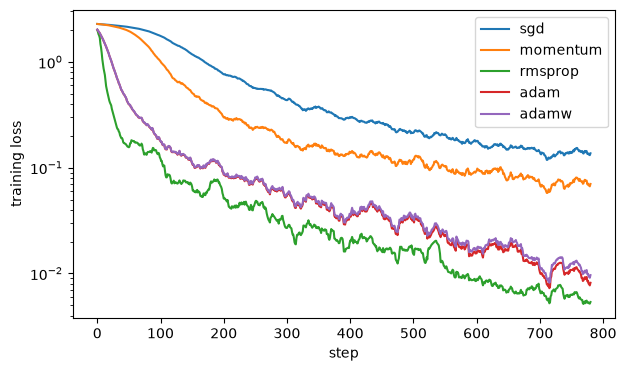

In [4]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

def load_digits_tensors(size=8, test_size=0.2, seed=0):
    """sklearn's bundled 8x8 handwritten digits (1,797 images, no download needed).
    Returns X_train, y_train, X_test, y_test with X shaped (N, 1, size, size) in [0, 1]."""
    d = load_digits()
    X = torch.tensor(d.images, dtype=torch.float32).unsqueeze(1) / 16.0
    if size != 8:
        X = F.interpolate(X, size=(size, size), mode="bilinear", align_corners=False)
    y = torch.tensor(d.target, dtype=torch.long)
    tr, te = train_test_split(np.arange(len(y)), test_size=test_size, random_state=seed, stratify=d.target)
    return X[tr], y[tr], X[te], y[te]
Xtr, ytr, Xte, yte = load_digits_tensors()
Xtr, Xte, ytr, yte = Xtr.flatten(1).to(device), Xte.flatten(1).to(device), ytr.to(device), yte.to(device)
def mlp(): return nn.Sequential(nn.Linear(64, 128), nn.Tanh(), nn.Linear(128, 128), nn.Tanh(), nn.Linear(128, 128), nn.Tanh(), nn.Linear(128, 10))
curves = {}
for kind, lr in {"sgd": 0.05, "momentum": 0.01, "rmsprop": 1e-3, "adam": 1e-3, "adamw": 1e-3}.items():
    seed_everything(0); m = mlp().to(device)
    o = Optimizer(m.parameters(), kind, lr, wd=0.05 if kind == "adamw" else 0.0); losses = []
    for s in range(800):
        idx = torch.randint(0, len(Xtr), (64,), device=device)
        loss = F.cross_entropy(m(Xtr[idx]), ytr[idx]); o.zero_grad(); loss.backward(); o.step(); losses.append(loss.item())
    with torch.no_grad(): acc = (m(Xte).argmax(1) == yte).float().mean().item()
    curves[kind] = np.convolve(losses, np.ones(20) / 20, "valid"); print(f"{kind:9s} test acc {acc:.3f}")
plt.figure(figsize=(7, 4))
for k, c in curves.items(): plt.plot(c, label=k)
plt.yscale("log"); plt.xlabel("step"); plt.ylabel("training loss"); plt.legend(); plt.show()

## Why AdamW, not "Adam + L2"?
With L2 regularisation the penalty gradient $\lambda\theta$ is added to $g$ and then **divided by $\sqrt{\hat v}$**. Parameters with large gradients barely get regularised. AdamW applies the decay directly to the weights, so every parameter shrinks at the same relative rate.

In [5]:
p_l2 = torch.tensor([1.0, 1.0], requires_grad=True); p_w = torch.tensor([1.0, 1.0], requires_grad=True)
o_l2, o_w = Optimizer([p_l2], "adam", 1e-2), Optimizer([p_w], "adamw", 1e-2, wd=0.1)
scale = torch.tensor([100.0, 0.01])                 # one parameter sees huge gradients, the other tiny ones
for _ in range(500):
    for p, o, l2 in [(p_l2, o_l2, True), (p_w, o_w, False)]:
        o.zero_grad(); loss = (scale * torch.randn(2) * p).sum() + (0.05 * (p ** 2).sum() if l2 else 0); loss.backward(); o.step()
print(f"Adam + L2 : weights {p_l2.detach().numpy().round(3)}  <- the large-gradient weight is barely regularised, the small-gradient one collapses")
print(f"AdamW     : weights {p_w.detach().numpy().round(3)}  <- both are shrunk by the same decoupled decay (the remaining gap is gradient noise)")

Adam + L2 : weights [1.007 0.006]  <- the large-gradient weight is barely regularised, the small-gradient one collapses
AdamW     : weights [0.39  0.529]  <- both are shrunk by the same decoupled decay (the remaining gap is gradient noise)
